Drive already mounted at /gdrive/; to attempt to forcibly remount, call drive.mount("/gdrive/", force_remount=True).
/gdrive/MyDrive
데이터 컬럼 목록: ['PH', 'Succunate', 'Lactate', 'Acetate', 'Propionat', 'Butyrate ', 'Total VFAs', 'sCOD ', 'TCOD', 'VS', 'TS', 'OLR', 'Flow rate', 'CH4']
Feature(X)와 Target(y)가 정상적으로 정의되었습니다. X shape: (69, 13), y shape: (69,)
예측값 일부: [  0.        333.4924423 368.0784663 396.0194175 351.9655602 301.8761062
 293.260274  305.2083333 268.6581207 271.5755026]
X shape: (69, 13), y shape: (69,)
Train MSE: 0.0000, R2: 1.0000
Test MSE: 13752.8222, R2: -1.1804


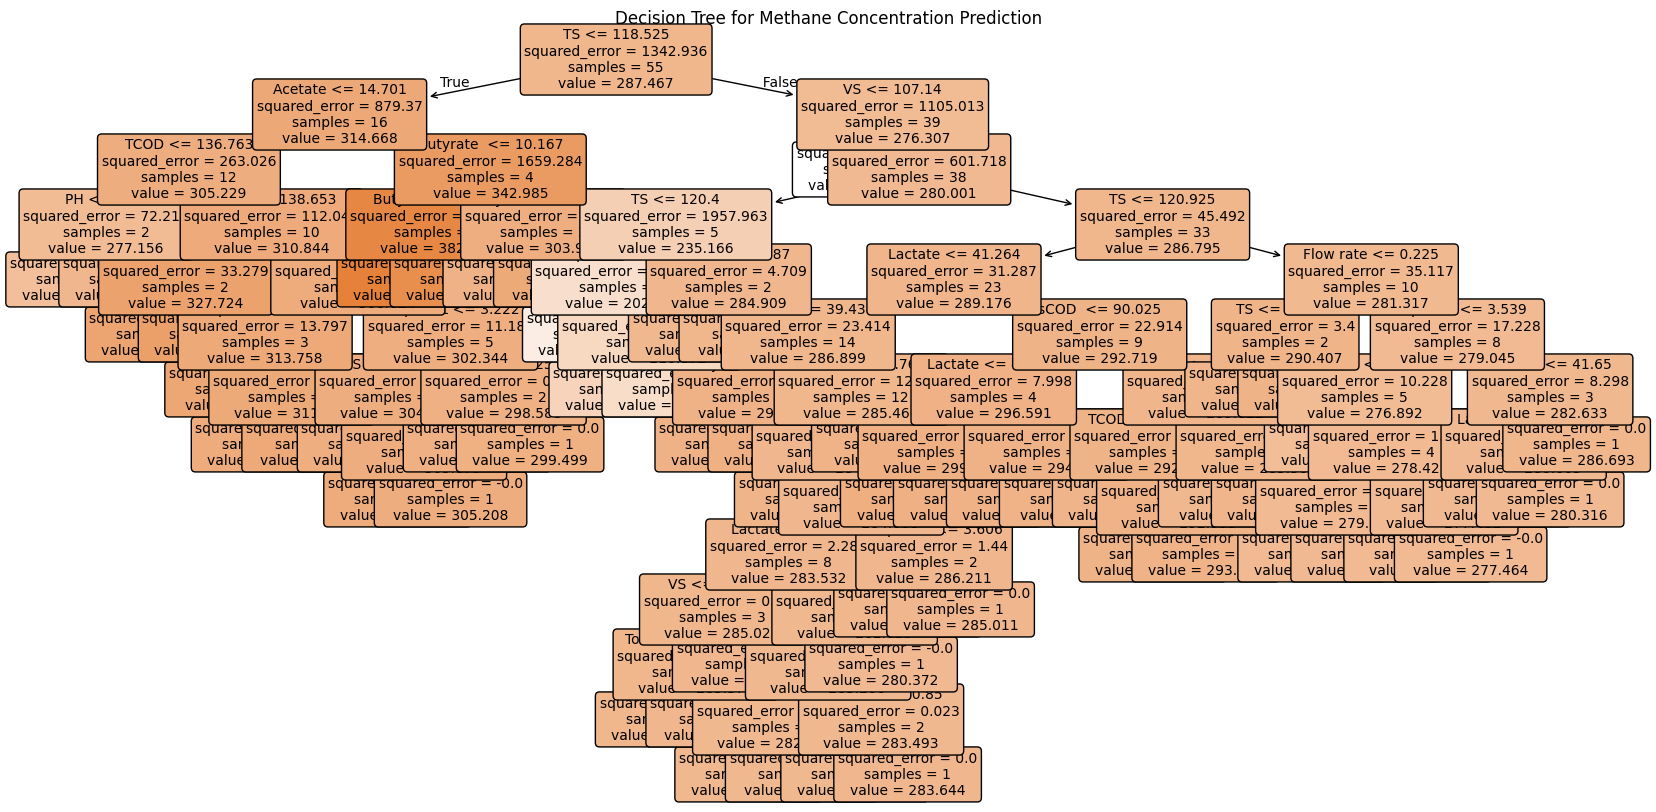

In [15]:
import pandas as pd
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount('/gdrive/')

# 현재 폴더로 이동
%cd /gdrive/MyDrive/

import pandas as pd

ipath = '/gdrive/MyDrive/'
iname = 'GODAS_1980-2022.nc'

file_path = "/gdrive/MyDrive/혐기성소화_자료정리_allv1.xlsx"
#df = pd.read_excel(file_path, sheet_name=0)

import pandas as pd
from sklearn.tree import DecisionTreeRegressor

# 데이터 불러오기
data = pd.read_csv("/gdrive/MyDrive/혐기성소화_자료정리_allv1_remove.csv")  # 실제 파일명으로 변경
data = pd.read_csv("/gdrive/MyDrive/JHM_2025_sort_utf.csv")
# 데이터 컬럼 확인
print("데이터 컬럼 목록:", list(data.columns))

# 타깃 컬럼 이름
target_column = "CH4"  # 실제 타깃 컬럼 이름으로 변경 가능

# Feature와 Target 자동 설정
if target_column in data.columns:
    X = data.drop(columns=[target_column])
    y = data[target_column]
    print(f"Feature(X)와 Target(y)가 정상적으로 정의되었습니다. X shape: {X.shape}, y shape: {y.shape}")
else:
    raise ValueError(f"타깃 컬럼 '{target_column}'이 데이터에 없습니다. 컬럼명을 확인해주세요.")

# 결정 트리 모델 학습
model = DecisionTreeRegressor(random_state=42)
model.fit(X, y)

# 예측
y_pred = model.predict(X)

# 예측 결과 일부 출력
print("예측값 일부:", y_pred[:10])



import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt



# 4. Feature와 Target 자동 설정
if target_column in data.columns:
    X = data.drop(columns=[target_column])
    y = data[target_column]
    print(f"X shape: {X.shape}, y shape: {y.shape}")
else:
    raise ValueError(f"타깃 컬럼 '{target_column}'이 데이터에 없습니다. 컬럼명을 확인해주세요.")

# 5. 학습용/검증용 데이터 분리
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 6. 결정 트리 모델 학습
model = DecisionTreeRegressor(random_state=42)
model.fit(X_train, y_train)

# 7. 예측
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

# 8. 성능 평가
train_mse = mean_squared_error(y_train, y_train_pred)
test_mse = mean_squared_error(y_test, y_test_pred)
train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

print(f"Train MSE: {train_mse:.4f}, R2: {train_r2:.4f}")
print(f"Test MSE: {test_mse:.4f}, R2: {test_r2:.4f}")

# 9. 결정 트리 시각화
plt.figure(figsize=(20,10))
plot_tree(model, feature_names=X.columns, filled=True, rounded=True, fontsize=10)
plt.title("Decision Tree for Methane Concentration Prediction")
plt.show()




Drive already mounted at /gdrive/; to attempt to forcibly remount, call drive.mount("/gdrive/", force_remount=True).
/gdrive/MyDrive
데이터 컬럼 목록: ['PH', 'Succunate', 'Lactate', 'Acetate', 'Propionat', 'Butyrate ', 'Total VFAs', 'sCOD ', 'TCOD', 'VS', 'TS', 'OLR', 'Flow rate', 'CH4']
X shape: (69, 13), y shape: (69,)
최적 하이퍼파라미터: {'max_depth': 3, 'min_samples_leaf': 4, 'min_samples_split': 2}
교차 검증 R² 점수 평균: -0.5450
Train MSE: 679.9607, R²: 0.4937
Test MSE: 8739.9048, R²: -0.3856


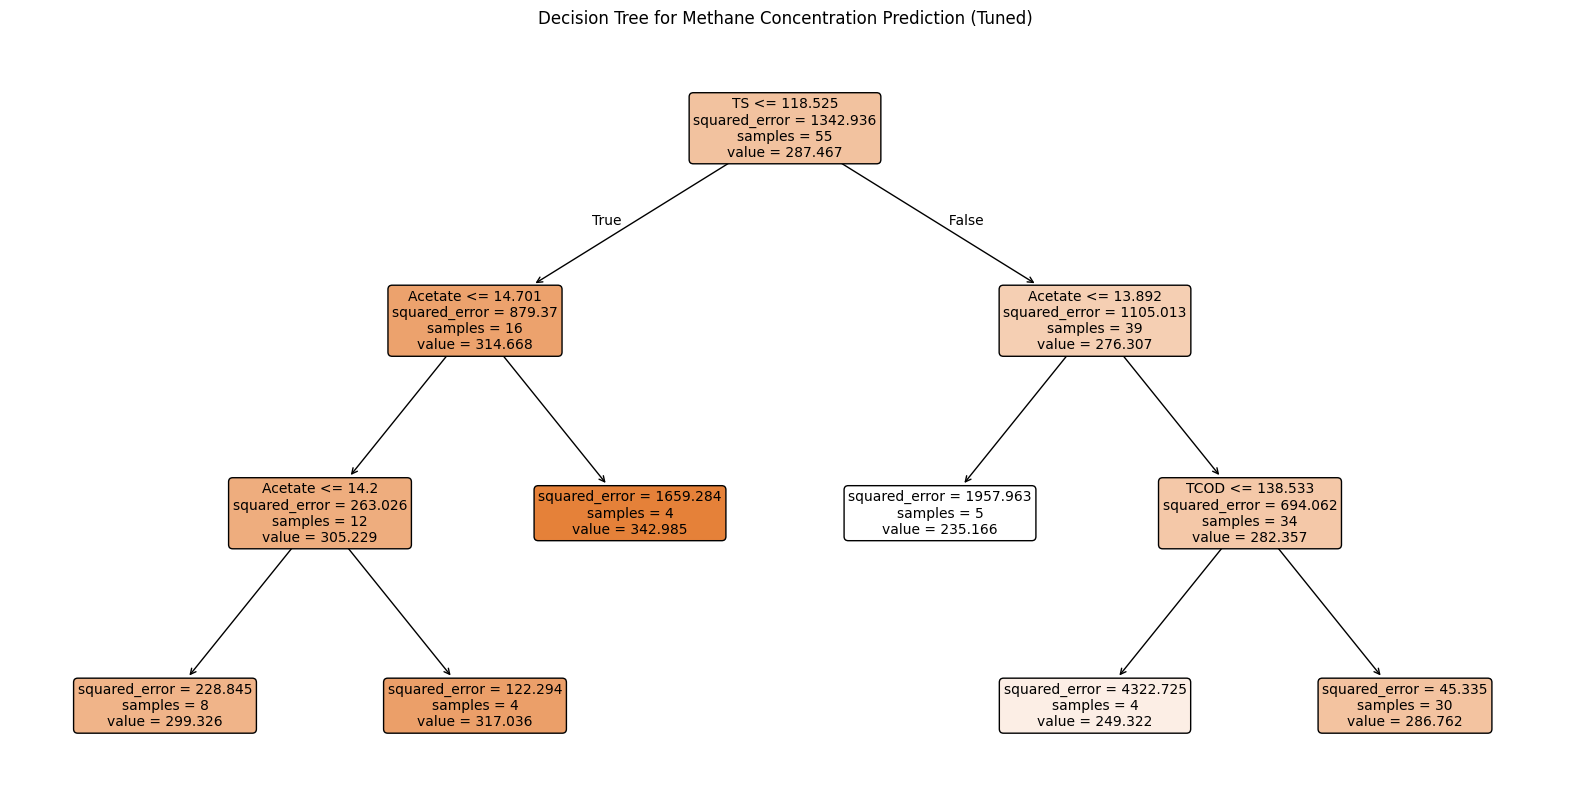

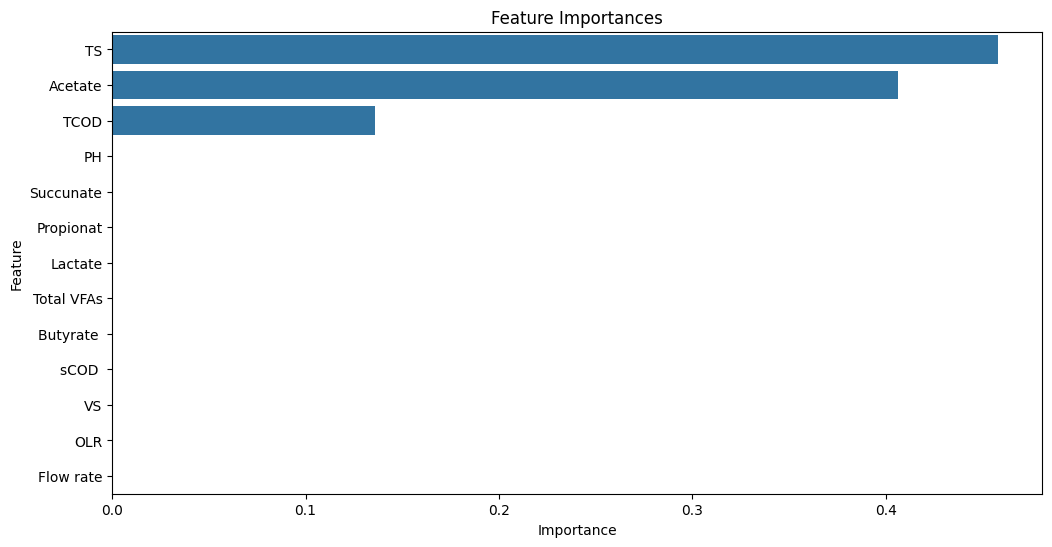

In [16]:
import pandas as pd
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
drive.mount('/gdrive/')

# 현재 폴더로 이동
%cd /gdrive/MyDrive/

import pandas as pd

ipath = '/gdrive/MyDrive/'
iname = 'GODAS_1980-2022.nc'

file_path = "/gdrive/MyDrive/혐기성소화_hy.xlsx"
df = pd.read_excel(file_path, sheet_name=0)

import pandas as pd
from sklearn.tree import DecisionTreeRegressor

# 데이터 불러오기
data = pd.read_csv("/gdrive/MyDrive/혐기성소화_자료정리_allv1_remove.csv")
data = pd.read_csv("/gdrive/MyDrive/JHM_2025_sort_utf.csv")   # 실제 파일명으로 변경


# 데이터 컬럼 확인
print("데이터 컬럼 목록:", list(data.columns))

# 타깃 컬럼 이름
target_column = "CH4"  # 실제 타깃 컬럼 이름으로 변경 가능
if target_column in data.columns:
    X = data.drop(columns=[target_column])
    y = data[target_column]
    print(f"X shape: {X.shape}, y shape: {y.shape}")
else:
    raise ValueError(f"타깃 컬럼 '{target_column}'이 데이터에 없습니다. 컬럼명을 확인해주세요.")

# 5. 학습용/검증용 데이터 분리
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 6. 하이퍼파라미터 튜닝을 위한 GridSearchCV 설정
param_grid = {
    'max_depth': [3, 5, 7, 9, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid_search = GridSearchCV(DecisionTreeRegressor(random_state=42),
                           param_grid,
                           cv=5,
                           scoring='r2',
                           n_jobs=-1)
grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
print("최적 하이퍼파라미터:", grid_search.best_params_)

# 7. 교차 검증 점수 확인
cv_scores = cross_val_score(best_model, X_train, y_train, cv=5, scoring='r2')
print(f"교차 검증 R² 점수 평균: {cv_scores.mean():.4f}")

# 8. 학습 및 예측
best_model.fit(X_train, y_train)
y_train_pred = best_model.predict(X_train)
y_test_pred = best_model.predict(X_test)

# 9. 성능 평가
train_mse = mean_squared_error(y_train, y_train_pred)
test_mse = mean_squared_error(y_test, y_test_pred)
train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

print(f"Train MSE: {train_mse:.4f}, R²: {train_r2:.4f}")
print(f"Test MSE: {test_mse:.4f}, R²: {test_r2:.4f}")

# 10. 결정 트리 시각화
plt.figure(figsize=(20,10))
plot_tree(best_model, feature_names=X.columns, filled=True, rounded=True, fontsize=10)
plt.title("Decision Tree for Methane Concentration Prediction (Tuned)")
plt.show()

# 11. Feature 중요도 시각화
feature_importances = pd.Series(best_model.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(12,6))
sns.barplot(x=feature_importances.values, y=feature_importances.index)
plt.title("Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()


Drive already mounted at /gdrive/; to attempt to forcibly remount, call drive.mount("/gdrive/", force_remount=True).
/gdrive/MyDrive
데이터 컬럼 목록: ['PH', 'Succunate', 'Lactate', 'Acetate', 'Propionat', 'Butyrate ', 'Total VFAs', 'sCOD ', 'TCOD', 'VS', 'TS', 'OLR', 'Flow rate', 'CH4']
X shape: (69, 13), y shape: (69,)
최적 하이퍼파라미터: {'max_depth': 3, 'min_samples_leaf': 4, 'min_samples_split': 2}
교차 검증 R² 점수 평균: -0.5450
전체 데이터 기준 MSE: 1644.3349, R²: 0.3072


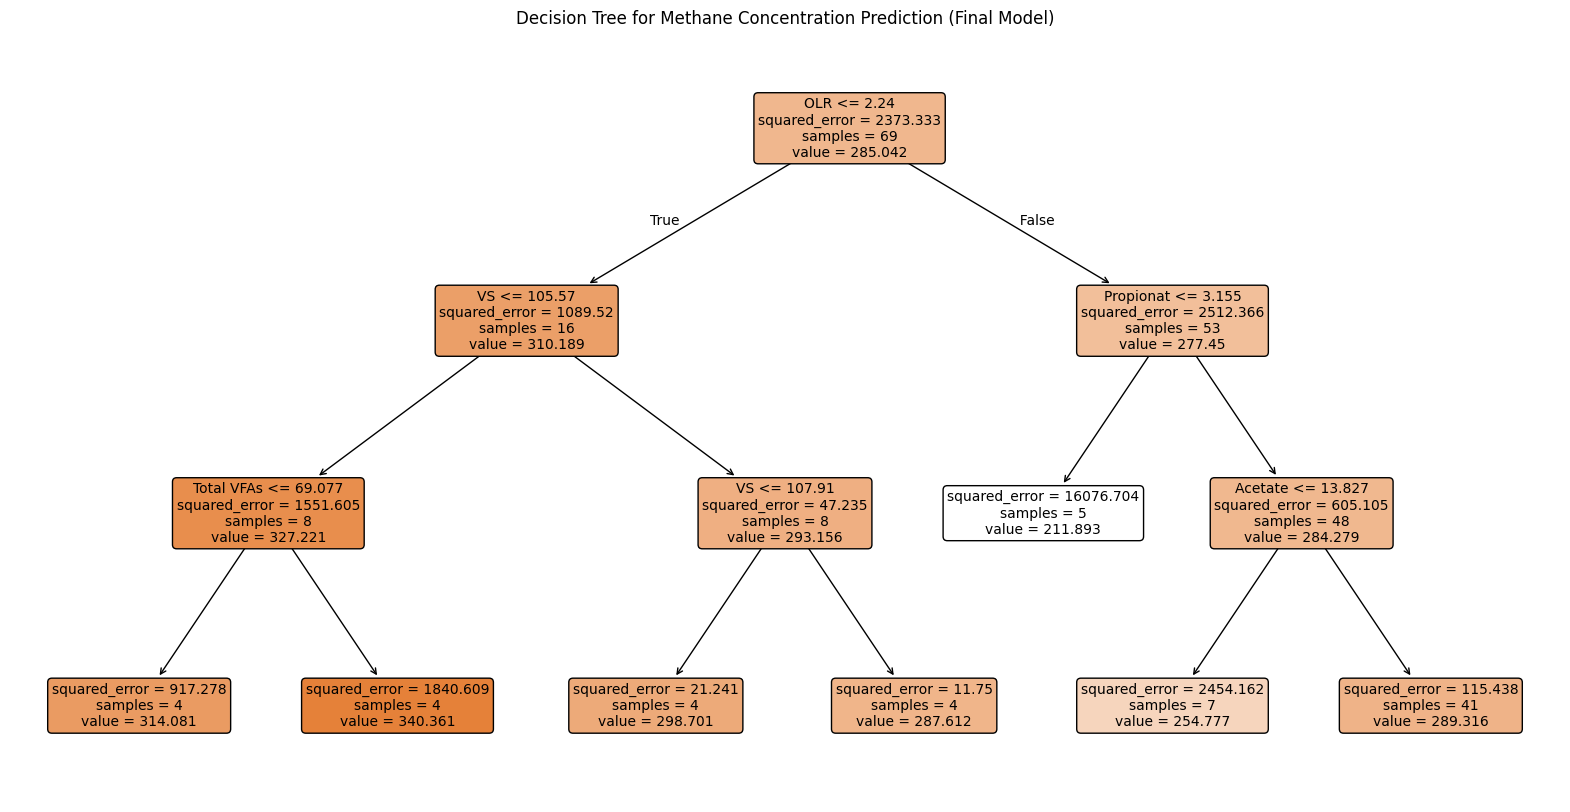

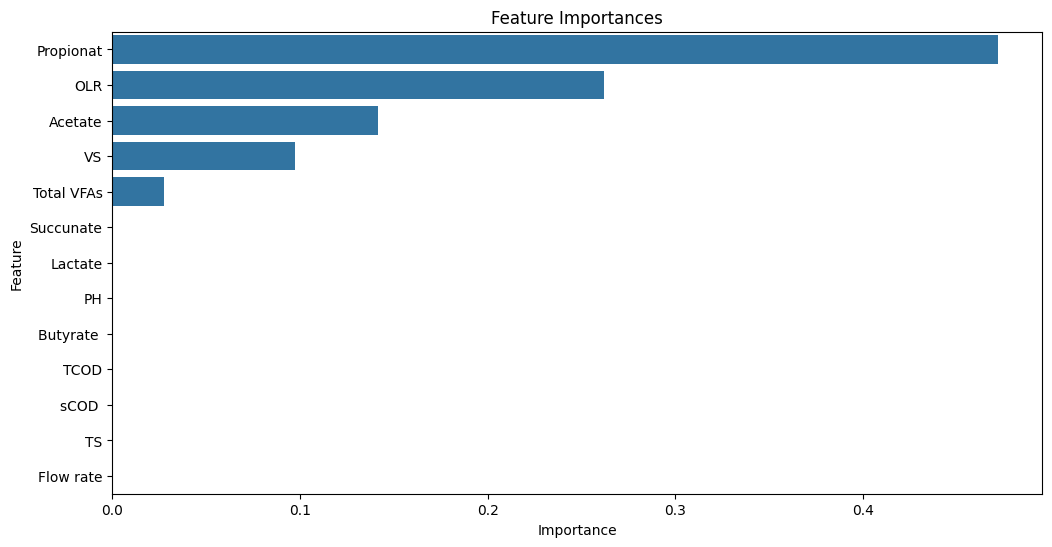

예측값이 'methane_predictions.csv' 파일로 저장되었습니다.


In [17]:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
drive.mount('/gdrive/')

# 현재 폴더로 이동
%cd /gdrive/MyDrive/

import pandas as pd

ipath = '/gdrive/MyDrive/'
iname = 'GODAS_1980-2022.nc'

file_path = "/gdrive/MyDrive/혐기성소화_hy.xlsx"
df = pd.read_excel(file_path, sheet_name=0)

import pandas as pd
from sklearn.tree import DecisionTreeRegressor

# 데이터 불러오기
data = pd.read_csv("/gdrive/MyDrive/혐기성소화_자료정리_allv1_remove.csv")
data = pd.read_csv("/gdrive/MyDrive/JHM_2025_sort_utf.csv")   # 실제 파일명으로 변경


# 데이터 컬럼 확인
print("데이터 컬럼 목록:", list(data.columns))

# 타깃 컬럼 이름
target_column = "CH4"  # 실제 타깃 컬럼 이름으로 변경 가능

# 4. Feature와 Target 자동 설정
if target_column in data.columns:
    X = data.drop(columns=[target_column])
    y = data[target_column]
    print(f"X shape: {X.shape}, y shape: {y.shape}")
else:
    raise ValueError(f"타깃 컬럼 '{target_column}'이 데이터에 없습니다. 컬럼명을 확인해주세요.")

# 5. 학습용/검증용 데이터 분리
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 6. 하이퍼파라미터 튜닝을 위한 GridSearchCV 설정
param_grid = {
    'max_depth': [3, 5, 7, 9, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid_search = GridSearchCV(DecisionTreeRegressor(random_state=42),
                           param_grid,
                           cv=5,
                           scoring='r2',
                           n_jobs=-1)
grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
print("최적 하이퍼파라미터:", grid_search.best_params_)

# 7. 교차 검증 점수 확인
cv_scores = cross_val_score(best_model, X_train, y_train, cv=5, scoring='r2')
print(f"교차 검증 R² 점수 평균: {cv_scores.mean():.4f}")

# 8. 학습 및 예측 (전체 데이터 포함)
best_model.fit(X, y)  # 전체 데이터로 재학습
y_pred = best_model.predict(X)

# 9. 성능 평가 (학습 데이터 기준)
mse = mean_squared_error(y, y_pred)
r2 = r2_score(y, y_pred)
print(f"전체 데이터 기준 MSE: {mse:.4f}, R²: {r2:.4f}")

# 10. 결정 트리 시각화
plt.figure(figsize=(20,10))
plot_tree(best_model, feature_names=X.columns, filled=True, rounded=True, fontsize=10)
plt.title("Decision Tree for Methane Concentration Prediction (Final Model)")
plt.show()

# 11. Feature 중요도 시각화
feature_importances = pd.Series(best_model.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(12,6))
sns.barplot(x=feature_importances.values, y=feature_importances.index)
plt.title("Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

# 12. 예측값 CSV로 저장
output = X.copy()
output[target_column + "_predicted"] = y_pred
output.to_csv("CH4_all.csv", index=False)
print("예측값이 'methane_predictions.csv' 파일로 저장되었습니다.")


In [18]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.base import RegressorMixin
from sklearn.metrics import mean_squared_error, r2_score

# 데이터 불러오기
data = pd.read_csv("/gdrive/MyDrive/혐기성소화_자료정리_allv1_remove.csv")  # 실제 파일명으로 변경


# 데이터 컬럼 확인
print("데이터 컬럼 목록:", list(data.columns))

# 타깃 컬럼 이름
target_column = "CH4"  # 실제 타깃 컬럼 이름으로 변경 가능

# 4. Feature와 Target 자동 설정
if target_column in data.columns:
    X = data.drop(columns=[target_column])
    y = data[target_column]
    print(f"X shape: {X.shape}, y shape: {y.shape}")
else:
    raise ValueError(f"타깃 컬럼 '{target_column}'이 데이터에 없습니다. 컬럼명을 확인해주세요.")

# 5. 학습용/검증용 데이터 분리
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 6. 하이퍼파라미터 튜닝을 위한 GridSearchCV 설정
param_grid = {
    'max_depth': [3, 5, 7, 9, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}


def train_and_plot_regression_surface(
    model: RegressorMixin,
    X: np.ndarray,
    y: np.ndarray,
    test_size: float = 0.2,
    random_state: int = 42,
    feature_idx: tuple = (0, 1),
    padding: float = 0.5,
    h: float = 0.05
):
    """
    모델 학습 + 회귀 결정 표면 시각화 함수 (2D 피처 전용)

    Parameters
    ----------
    model : RegressorMixin
        Scikit-learn 회귀 모델 (fit 지원)
    X : array-like, shape (n_samples, n_features)
        입력 데이터 (n_features >= 2 권장)
    y : array-like, shape (n_samples,)
        타깃 값
    test_size : float, default=0.2
        테스트셋 비율
    random_state : int
        랜덤 시드
    feature_idx : tuple, default=(0,1)
        2차원 시각화를 위해 사용할 피처 인덱스
    padding : float, default=0.5
        그래프 여백
    h : float, default=0.05
        결정 표면 해상도
    """
    from sklearn.model_selection import train_test_split

    # 1. 학습/검증 데이터 분리
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state
    )

    # 2. 모델 학습
    model.fit(X_train, y_train)

    # 3. 성능 평가
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    print(f"Test MSE: {mse:.4f}, R²: {r2:.4f}")

    # 4. 두 개의 피처 선택
    X2 = X[:, feature_idx]

    x_min, x_max = X2[:, 0].min() - padding, X2[:, 0].max() + padding
    y_min, y_max = X2[:, 1].min() - padding, X2[:, 1].max() + padding
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))
    grid = np.c_[xx.ravel(), yy.ravel()]

    # 5. 회귀 예측값
    Z = model.predict(grid)
    Z = Z.reshape(xx.shape)

    # 6. 결정 표면 시각화
    plt.figure(figsize=(8,6))
    cs = plt.contourf(xx, yy, Z, cmap="viridis", alpha=0.7)
    plt.colorbar(cs, label="Predicted value")

    # 7. 실제 데이터 점 산점도
    sc = plt.scatter(X2[:, 0], X2[:, 1], c=y, edgecolor="k", cmap="viridis", s=50)
    plt.colorbar(sc, label="Actual value")

    plt.xlabel(f"Feature {feature_idx[0]}")
    plt.ylabel(f"Feature {feature_idx[1]}")
    plt.title("Regression Decision Surface")
    plt.show()


데이터 컬럼 목록: ['pH', 'BOD5', 'CODcr', 'CODMn', 'TCOD', 'SCOD', 'NaCl', 'Alkali', 'rpm', 'Temperature', 'Time', 'VS', 'TS', 'COD load', 'VS load', 'size', 'cleaning', 'Charc', 'mixing', 'Char', 'SRT', 'Impeller', 'type', 'CH4']
X shape: (39, 23), y shape: (39,)


데이터 컬럼 목록: ['PH', 'Succunate', 'Lactate', 'Acetate', 'Propionat', 'Butyrate ', 'Total VFAs', 'sCOD ', 'TCOD', 'VS', 'TS', 'OLR', 'Flow rate', 'CH4']
X shape: (69, 13), y shape: (69,)


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeRegressor was fitted with feature names
  warnings.warn(


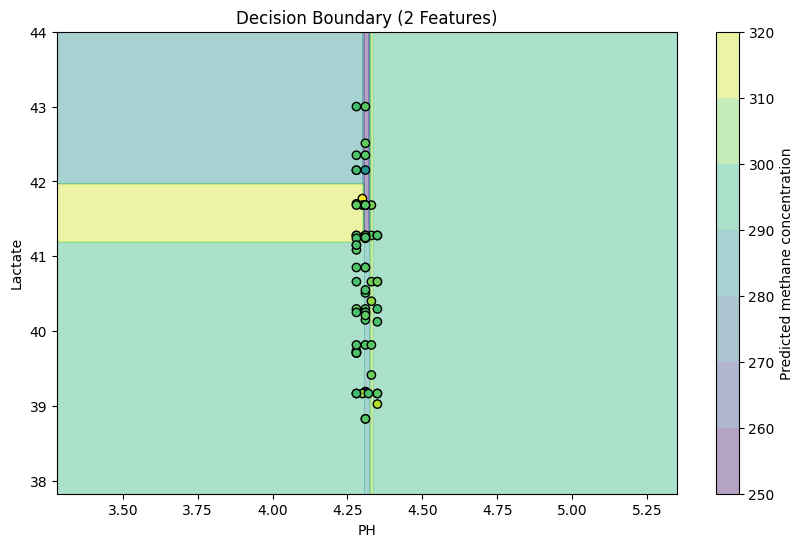

In [19]:
# -------------------------------
# 13. 결정 경계 시각화 (feature 2개만 사용)
# -------------------------------

# 데이터 불러오기
data = pd.read_csv("/gdrive/MyDrive/혐기성소화_자료정리_allv1_remove.csv")
data = pd.read_csv("/gdrive/MyDrive/JHM_2025_sort_utf.csv")   # 실제 파일명으로 변경


# 데이터 컬럼 확인
print("데이터 컬럼 목록:", list(data.columns))

# 타깃 컬럼 이름
target_column = "CH4"  # 실제 타깃 컬럼 이름으로 변경 가능

# 4. Feature와 Target 자동 설정
if target_column in data.columns:
    X = data.drop(columns=[target_column])
    y = data[target_column]
    print(f"X shape: {X.shape}, y shape: {y.shape}")
else:
    raise ValueError(f"타깃 컬럼 '{target_column}'이 데이터에 없습니다. 컬럼명을 확인해주세요.")

# 5. 학습용/검증용 데이터 분리
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 6. 하이퍼파라미터 튜닝을 위한 GridSearchCV 설정
param_grid = {
    'max_depth': [3, 5, 7, 9, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}


# 1) feature 2개만 선택 (원하는 feature명으로 변경)
feature_x = X.columns[0]
feature_y = X.columns[2]

X_2d = X[[feature_x, feature_y]]
y_2d = y

# 2) 데이터 분리
X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(X_2d, y_2d, test_size=0.2, random_state=42)

# 3) 모델 학습 (앞에서 찾은 최적 파라미터 사용)
model_2d = DecisionTreeRegressor(**grid_search.best_params_, random_state=42)
model_2d.fit(X_train_2d, y_train_2d)

# 4) meshgrid 생성 (결정경계용)
import numpy as np
x_min, x_max = X_2d[feature_x].min() - 1, X_2d[feature_x].max() + 1
y_min, y_max = X_2d[feature_y].min() - 1, X_2d[feature_y].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

# 5) meshgrid로 예측
Z = model_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# 6) 시각화
plt.figure(figsize=(10, 6))
# 결정 경계 영역 (회색조)
cs = plt.contourf(xx, yy, Z, alpha=0.4, cmap="viridis")
plt.colorbar(cs, label="Predicted methane concentration")

# 실제 데이터 점
plt.scatter(X_2d[feature_x], X_2d[feature_y], c=y_2d, edgecolor="k", cmap="viridis")
plt.xlabel(feature_x)
plt.ylabel(feature_y)
plt.title("Decision Boundary (2 Features)")
plt.show()


데이터 컬럼 목록: ['pH', 'BOD5', 'CODcr', 'CODMn', 'TCOD', 'SCOD', 'NaCl', 'Alkali', 'rpm', 'Temperature', 'Time', 'VS', 'TS', 'COD load', 'VS load', 'size', 'cleaning', 'Charc', 'mixing', 'Char', 'SRT', 'Impeller', 'type', 'CH4']
X shape: (39, 23), y shape: (39,)


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeRegressor was fitted with feature names
  warnings.warn(


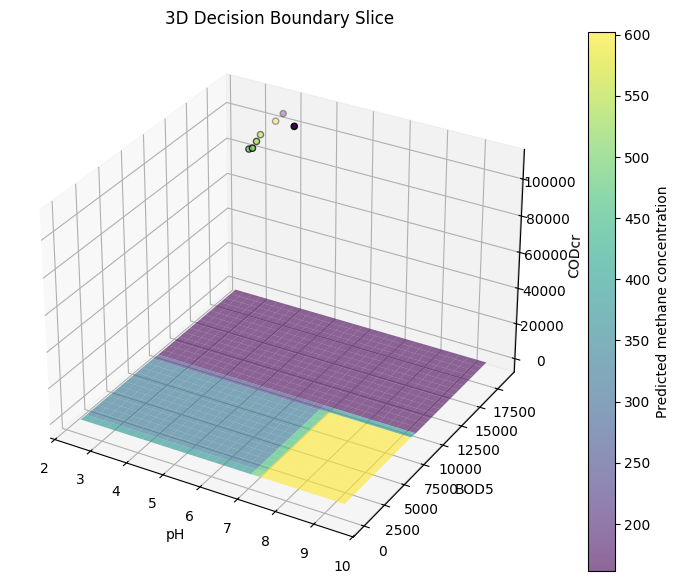

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split


# 데이터 불러오기
data = pd.read_csv("/gdrive/MyDrive/혐기성소화_자료정리_allv1_remove.csv")  # 실제 파일명으로 변경


# 데이터 컬럼 확인
print("데이터 컬럼 목록:", list(data.columns))

# 타깃 컬럼 이름
target_column = "CH4"  # 실제 타깃 컬럼 이름으로 변경 가능

# 4. Feature와 Target 자동 설정
if target_column in data.columns:
    X = data.drop(columns=[target_column])
    y = data[target_column]
    print(f"X shape: {X.shape}, y shape: {y.shape}")
else:
    raise ValueError(f"타깃 컬럼 '{target_column}'이 데이터에 없습니다. 컬럼명을 확인해주세요.")

# 5. 학습용/검증용 데이터 분리
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 6. 하이퍼파라미터 튜닝을 위한 GridSearchCV 설정
param_grid = {
    'max_depth': [3, 5, 7, 9, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}


# -------------------------------
# 1) Feature 3개 선택 (원하는 feature명으로 수정 가능)
# -------------------------------
feature_x = X.columns[0]
feature_y = X.columns[1]
feature_z = X.columns[2]

X_3d = X[[feature_x, feature_y, feature_z]]
y_3d = y

# -------------------------------
# 2) Train/Test Split
# -------------------------------
X_train_3d, X_test_3d, y_train_3d, y_test_3d = train_test_split(
    X_3d, y_3d, test_size=0.2, random_state=42
)

# -------------------------------
# 3) 모델 학습 (기존 best_params 활용)
# -------------------------------
model_3d = DecisionTreeRegressor(**grid_search.best_params_, random_state=42)
model_3d.fit(X_train_3d, y_train_3d)

# -------------------------------
# 4) Meshgrid 생성 (결정경계용)
# -------------------------------
x_min, x_max = X_3d[feature_x].min() - 1, X_3d[feature_x].max() + 1
y_min, y_max = X_3d[feature_y].min() - 1, X_3d[feature_y].max() + 1
z_min, z_max = X_3d[feature_z].min() - 1, X_3d[feature_z].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 30),
    np.linspace(y_min, y_max, 30)
)

# z축은 여러 slice 중 하나를 고정해서 시각화
z_fixed = np.median(X_3d[feature_z])  # 중간값으로 slice
zz = np.full_like(xx, z_fixed)

# -------------------------------
# 5) 예측값 계산
# -------------------------------
Z_pred = model_3d.predict(np.c_[xx.ravel(), yy.ravel(), zz.ravel()])
Z_pred = Z_pred.reshape(xx.shape)

# -------------------------------
# 6) 시각화 (3D)
# -------------------------------
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

# 결정경계 면
surf = ax.plot_surface(xx, yy, Z_pred, cmap="viridis", alpha=0.6)

# 실제 데이터 점
sc = ax.scatter(
    X_3d[feature_x], X_3d[feature_y], X_3d[feature_z],
    c=y_3d, cmap="viridis", edgecolor="k"
)

ax.set_xlabel(feature_x)
ax.set_ylabel(feature_y)
ax.set_zlabel(feature_z)
ax.set_title("3D Decision Boundary Slice")
fig.colorbar(surf, ax=ax, label="Predicted methane concentration")
plt.show()


In [21]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.decomposition import PCA


# 데이터 불러오기
data = pd.read_csv("/gdrive/MyDrive/혐기성소화_자료정리_allv1_remove.csv")  # 실제 파일명으로 변경


# 데이터 컬럼 확인
print("데이터 컬럼 목록:", list(data.columns))

# 타깃 컬럼 이름
target_column = "CH4"  # 실제 타깃 컬럼 이름으로 변경 가능

# 4. Feature와 Target 자동 설정
if target_column in data.columns:
    X = data.drop(columns=[target_column])
    y = data[target_column]
    print(f"X shape: {X.shape}, y shape: {y.shape}")
else:
    raise ValueError(f"타깃 컬럼 '{target_column}'이 데이터에 없습니다. 컬럼명을 확인해주세요.")

# 5. 학습용/검증용 데이터 분리
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 6. 하이퍼파라미터 튜닝을 위한 GridSearchCV 설정
param_grid = {
    'max_depth': [3, 5, 7, 9, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}


def plot_decision_boundary(X, y, max_depth=5):
    n_features = X.shape[1]

    # 모델 정의
    model = DecisionTreeRegressor(max_depth=max_depth, random_state=42)

    # case 1: 2D (feature 2개)
    if n_features == 2:
        model.fit(X, y)
        x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
        y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
        xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                             np.linspace(y_min, y_max, 300))
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

        plt.figure(figsize=(8, 6))
        plt.contourf(xx, yy, Z, alpha=0.6, cmap="viridis")
        plt.scatter(X[:, 0], X[:, 1], c=y, cmap="viridis", edgecolor="k", s=50)
        plt.title("Decision Boundary (2 features)")
        plt.xlabel("Feature 1")
        plt.ylabel("Feature 2")
        plt.colorbar(label="Prediction")
        plt.show()

    # case 2: 3D (feature 3개)
    elif n_features == 3:
        model.fit(X, y)

        fig = plt.figure(figsize=(10, 7))
        ax = fig.add_subplot(111, projection="3d")
        scatter = ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=y, cmap="viridis", s=50)

        ax.set_title("Decision Boundary (3 features)")
        ax.set_xlabel("Feature 1")
        ax.set_ylabel("Feature 2")
        ax.set_zlabel("Feature 3")
        fig.colorbar(scatter, label="Prediction")
        plt.show()

    # case 3: 4D 이상 (PCA → 2D 축소 후 경계 그림)
    else:
        pca = PCA(n_components=2)
        X_pca = pca.fit_transform(X)

        model.fit(X_pca, y)
        x_min, x_max = X_pca[:, 0].min() - 1, X_pca[:, 0].max() + 1
        y_min, y_max = X_pca[:, 1].min() - 1, X_pca[:, 1].max() + 1
        xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                             np.linspace(y_min, y_max, 300))
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

        plt.figure(figsize=(8, 6))
        plt.contourf(xx, yy, Z, alpha=0.6, cmap="viridis")
        plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap="viridis", edgecolor="k", s=50)
        plt.title(f"Decision Boundary ({n_features} features via PCA)")
        plt.xlabel("PCA Component 1")
        plt.ylabel("PCA Component 2")
        plt.colorbar(label="Prediction")
        plt.show()


데이터 컬럼 목록: ['pH', 'BOD5', 'CODcr', 'CODMn', 'TCOD', 'SCOD', 'NaCl', 'Alkali', 'rpm', 'Temperature', 'Time', 'VS', 'TS', 'COD load', 'VS load', 'size', 'cleaning', 'Charc', 'mixing', 'Char', 'SRT', 'Impeller', 'type', 'CH4']
X shape: (39, 23), y shape: (39,)


In [ ]:
from sklearn.decomposition import PCA
import numpy as np
from sklearn.impute import SimpleImputer
import matplotlib.pyplot as plt


# 데이터 불러오기
data = pd.read_csv("/gdrive/MyDrive/혐기성소화_자료정리_allv1_remove.csv")  # 실제 파일명으로 변경


# 데이터 컬럼 확인
print("데이터 컬럼 목록:", list(data.columns))

# 타깃 컬럼 이름
target_column = "CH4"  # 실제 타깃 컬럼 이름으로 변경 가능

# 4. Feature와 Target 자동 설정
if target_column in data.columns:
    X = data.drop(columns=[target_column])
    y = data[target_column]
    print(f"X shape: {X.shape}, y shape: {y.shape}")
else:
    raise ValueError(f"타깃 컬럼 '{target_column}'이 데이터에 없습니다. 컬럼명을 확인해주세요.")

# 5. 학습용/검증용 데이터 분리
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 6. 하이퍼파라미터 튜닝을 위한 GridSearchCV 설정
param_grid = {
    'max_depth': [3, 5, 7, 9, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# 4개 feature 선택 (앞에서 4개만 예시)
features_4 = X.iloc[:, :4]
X_4 = features_4.values

# Impute missing values before PCA
imputer = SimpleImputer(missing_values=np.nan, strategy='mean')
X_4_imputed = imputer.fit_transform(X_4)

# PCA로 2차원 축소
pca = PCA(n_components=2)
X_4_pca = pca.fit_transform(X_4_imputed)

# 2D 변환된 데이터로 모델 재학습
model_4 = DecisionTreeRegressor(max_depth=5, random_state=42)
model_4.fit(X_4_pca, y)

# 결정 경계 시각화를 위한 meshgrid 생성
x_min, x_max = X_4_pca[:, 0].min() - 1, X_4_pca[:, 0].max() + 1
y_min, y_max = X_4_pca[:, 1].min() - 1, X_4_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                     np.linspace(y_min, y_max, 300))

# 예측값 계산
Z = model_4.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# 시각화
plt.figure(figsize=(10, 6))
contour = plt.contourf(xx, yy, Z, alpha=0.6, cmap="viridis")
scatter = plt.scatter(X_4_pca[:, 0], X_4_pca[:, 1], c=y, cmap="viridis", edgecolor="k", s=50)
plt.colorbar(contour, label="Predicted methane concentration")
plt.title("Decision Boundary with 4 Features (via PCA)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

데이터 컬럼 목록: ['pH', 'BOD5', 'CODcr', 'CODMn', 'TCOD', 'SCOD', 'NaCl', 'Alkali', 'rpm', '온도', 'Time', 'VS', 'TS', 'COD load', 'VS load', 'size', 'cleaning', 'Charc', 'mixing', 'Char', 'SRT', 'Impeller', 'type', 'CH4']
X shape: (39, 23), y shape: (39,)


ValueError: Input X contains NaN.
PCA does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values